# Reading TensorBoard Logs

This notebook demonstrates how to read training and test metrics from TensorBoard logs.

In [1]:
from tensorboard.backend.event_processing import event_accumulator
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

## Load TensorBoard Logs

In [3]:
# Set path to experiment log directory
log_dir = Path('../experiment/faust/ulrssm-20260311-222324/log')  # Update with your experiment path

# Load event file
ea = event_accumulator.EventAccumulator(str(log_dir))
ea.Reload()

# Show available scalar tags
print("Available scalar tags:")
for tag in ea.Tags()['scalars']:
    print(f"  {tag}")

Available scalar tags:
  loss/train/bij_loss
  loss/train/orth_loss
  loss/train/align_loss
  loss/train/total
  lr/feature_extractor
  loss/test/bij_loss
  loss/test/orth_loss
  loss/test/align_loss
  metric/test/geodist
  metric/test/geodist/auc
  metric/best-geodist


## Read Specific Metrics

In [4]:
def read_scalar(ea, tag):
    """Read scalar metric and return as DataFrame."""
    events = ea.Scalars(tag)
    return pd.DataFrame({
        'step': [e.step for e in events],
        'value': [e.value for e in events]
    })

# Read training loss
train_loss = read_scalar(ea, 'loss/train/total')
print("Training loss:")
print(train_loss.head())

Training loss:
   step       value
0     6  519.968506
1    16  738.342407
2    17  718.434448
3    24  660.637329
4    29  659.383972


## Plot Metrics

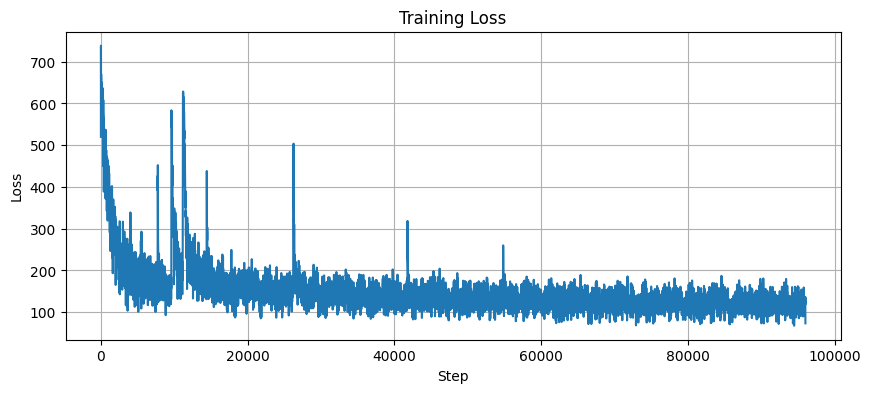

In [5]:
# Plot training loss
plt.figure(figsize=(10, 4))
plt.plot(train_loss['step'], train_loss['value'])
plt.xlabel('Step')
plt.ylabel('Loss')
plt.title('Training Loss')
plt.grid(True)
plt.show()

## Read Multiple Metrics

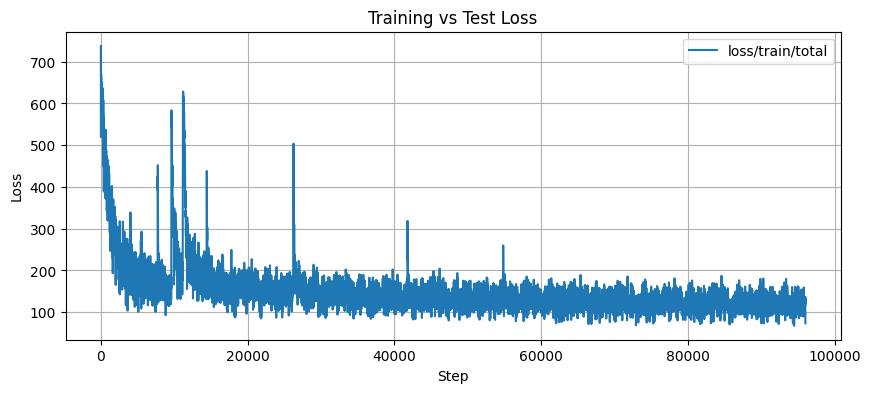

In [6]:
# Read multiple metrics
tags = ['loss/train/total', 'loss/test/total']
metrics = {tag: read_scalar(ea, tag) for tag in tags if tag in ea.Tags()['scalars']}

# Plot comparison
plt.figure(figsize=(10, 4))
for tag, df in metrics.items():
    plt.plot(df['step'], df['value'], label=tag)
plt.xlabel('Step')
plt.ylabel('Loss')
plt.title('Training vs Test Loss')
plt.legend()
plt.grid(True)
plt.show()